# Section 1 ? Experiment 2??????????

??????????????????????????????????
?? `lif/model.py` ? snnTorch LIF ?????????????????????????????

?????/???? ?65 mV??? ?50 mV?????? 20 ms??? 10 M????? 2 ms?Euler ?? 0.1 ms??? 2000 ms?

??? Notebook ??????????????? `results/` ??????????????????

In [1]:
import sys, json, csv, platform
from pathlib import Path
from dataclasses import asdict, replace
import numpy as np
import matplotlib.pyplot as plt
import torch, snntorch
from IPython.display import display, Markdown

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'lif/model.py').is_file())
sys.path.insert(0, str(root))
from lif.model import SimulationParameters, simulate_experiment
out = root / 'lif/section1_experiment2/results'
out.mkdir(parents=True, exist_ok=True)
p = SimulationParameters()
currents = [0, 0.5, 1, 1.4, 1.49, 1.5, 1.51, 1.6, 1.8, 2, 2.5, 3, 4, 5, 8, 10]
critical = (p.threshold - p.rest) / p.resistance
metadata = {'parameters': asdict(p), 'currents_nA': currents, 'backend': 'snntorch',
            'python': platform.python_version(), 'numpy': np.__version__,
            'torch': str(torch.__version__), 'snntorch': snntorch.__version__,
            'platform': platform.platform(), 'device': 'cpu'}
(out / 'parameters.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print(f'Critical current: {critical:g} nA')

Critical current: 1.5 nA


## ???????

????? = ??????? / 2 ???? ISI ??????????????????????????????? 0?????????????????????

????????????? $I>I_c$ ???????????
$$t_{\mathrm{int}}=\tau_m\ln\frac{RI}{RI-(V_{th}-V_{rest})},\qquad
f_\infty=\frac{1000}{t_{\mathrm{int}}+t_{ref}}.$$
??????? ms?????????????????????????????????

In [2]:
rows, traces = [], {}
for current in currents:
    data = simulate_experiment(replace(p, current=float(current)))
    traces[current] = data
    times = data['time_ms'][data['spikes'].astype(bool)]
    isi = np.diff(times)
    theory = 0.0 if current <= critical else 1000 / (p.refractory + p.tau * np.log(current / (current - critical)))
    rows.append({'current_nA': current, 'spike_count': len(times),
                 'average_rate_Hz': len(times) / (p.duration / 1000),
                 'first_spike_ms': float(times[0]) if len(times) else None,
                 'mean_ISI_ms': float(isi.mean()) if len(isi) else None,
                 'theory_steady_rate_Hz': theory})
    assert np.all(data['voltage'][data['spikes'].astype(bool)] == p.rest)
    if current <= critical:
        assert len(times) == 0
    else:
        assert len(times) >= 2
        assert np.all(isi > p.refractory)
        # Independent Euler solution predicts each inter-spike interval.
        k = int(np.ceil(np.log1p(-critical/current) / np.log1p(-p.dt/p.tau)))
        np.testing.assert_allclose(isi, k * p.dt + p.refractory, atol=p.dt + 1e-6, rtol=0)
    print(f'I={current:5.2f} nA: spikes={len(times):3d}, rate={rows[-1]["average_rate_Hz"]:6.1f} Hz', flush=True)
with (out / 'summary.csv').open('w', newline='', encoding='utf-8-sig') as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader(); writer.writerows(rows)
np.savez_compressed(out / 'traces.npz', currents_nA=currents,
                    time_ms=traces[0]['time_ms'],
                    voltage_mV=np.stack([traces[i]['voltage'] for i in currents]),
                    spikes=np.stack([traces[i]['spikes'] for i in currents]),
                    window_rate_Hz=np.stack([traces[i]['rate'] for i in currents]))
assert np.all(np.diff([r['average_rate_Hz'] for r in rows]) >= 0)
print('Reset, subthreshold, ISI and monotonicity checks passed.')

I= 0.00 nA: spikes=  0, rate=   0.0 Hz
I= 0.50 nA: spikes=  0, rate=   0.0 Hz
I= 1.00 nA: spikes=  0, rate=   0.0 Hz
I= 1.40 nA: spikes=  0, rate=   0.0 Hz
I= 1.49 nA: spikes=  0, rate=   0.0 Hz
I= 1.50 nA: spikes=  0, rate=   0.0 Hz
I= 1.51 nA: spikes= 19, rate=   9.5 Hz
I= 1.60 nA: spikes= 34, rate=  17.0 Hz
I= 1.80 nA: spikes= 52, rate=  26.0 Hz
I= 2.00 nA: spikes= 67, rate=  33.5 Hz
I= 2.50 nA: spikes= 98, rate=  49.0 Hz
I= 3.00 nA: spikes=125, rate=  62.5 Hz
I= 4.00 nA: spikes=175, rate=  87.5 Hz
I= 5.00 nA: spikes=217, rate= 108.5 Hz
I= 8.00 nA: spikes=322, rate= 161.0 Hz
I=10.00 nA: spikes=377, rate= 188.5 Hz
Reset, subthreshold, ISI and monotonicity checks passed.


In [3]:
def fmt(value):
    return '?' if value is None else f'{value:.3f}'
header = '| ?? nA | ???? | ?? Hz | ???? ms | ?? ISI ms |\n|---:|---:|---:|---:|---:|'
table = header + '\n' + '\n'.join(
    f"| {r['current_nA']:g} | {r['spike_count']} | {r['average_rate_Hz']:.1f} | {fmt(r['first_spike_ms'])} | {fmt(r['mean_ISI_ms'])} |"
    for r in rows)
display(Markdown(table))

| ?? nA | ???? | ?? Hz | ???? ms | ?? ISI ms |
|---:|---:|---:|---:|---:|
| 0 | 0 | 0.0 | ? | ? |
| 0.5 | 0 | 0.0 | ? | ? |
| 1 | 0 | 0.0 | ? | ? |
| 1.4 | 0 | 0.0 | ? | ? |
| 1.49 | 0 | 0.0 | ? | ? |
| 1.5 | 0 | 0.0 | ? | ? |
| 1.51 | 19 | 9.5 | 100.200 | 102.200 |
| 1.6 | 34 | 17.0 | 55.400 | 57.400 |
| 1.8 | 52 | 26.0 | 35.800 | 37.800 |
| 2 | 67 | 33.5 | 27.700 | 29.700 |
| 2.5 | 98 | 49.0 | 18.300 | 20.300 |
| 3 | 125 | 62.5 | 13.900 | 15.900 |
| 4 | 175 | 87.5 | 9.400 | 11.400 |
| 5 | 217 | 108.5 | 7.200 | 9.200 |
| 8 | 322 | 161.0 | 4.200 | 6.200 |
| 10 | 377 | 188.5 | 3.300 | 5.300 |

## ?????

???????? 200 ms???????????????????????? 2000 ms?????????? `traces.npz`?

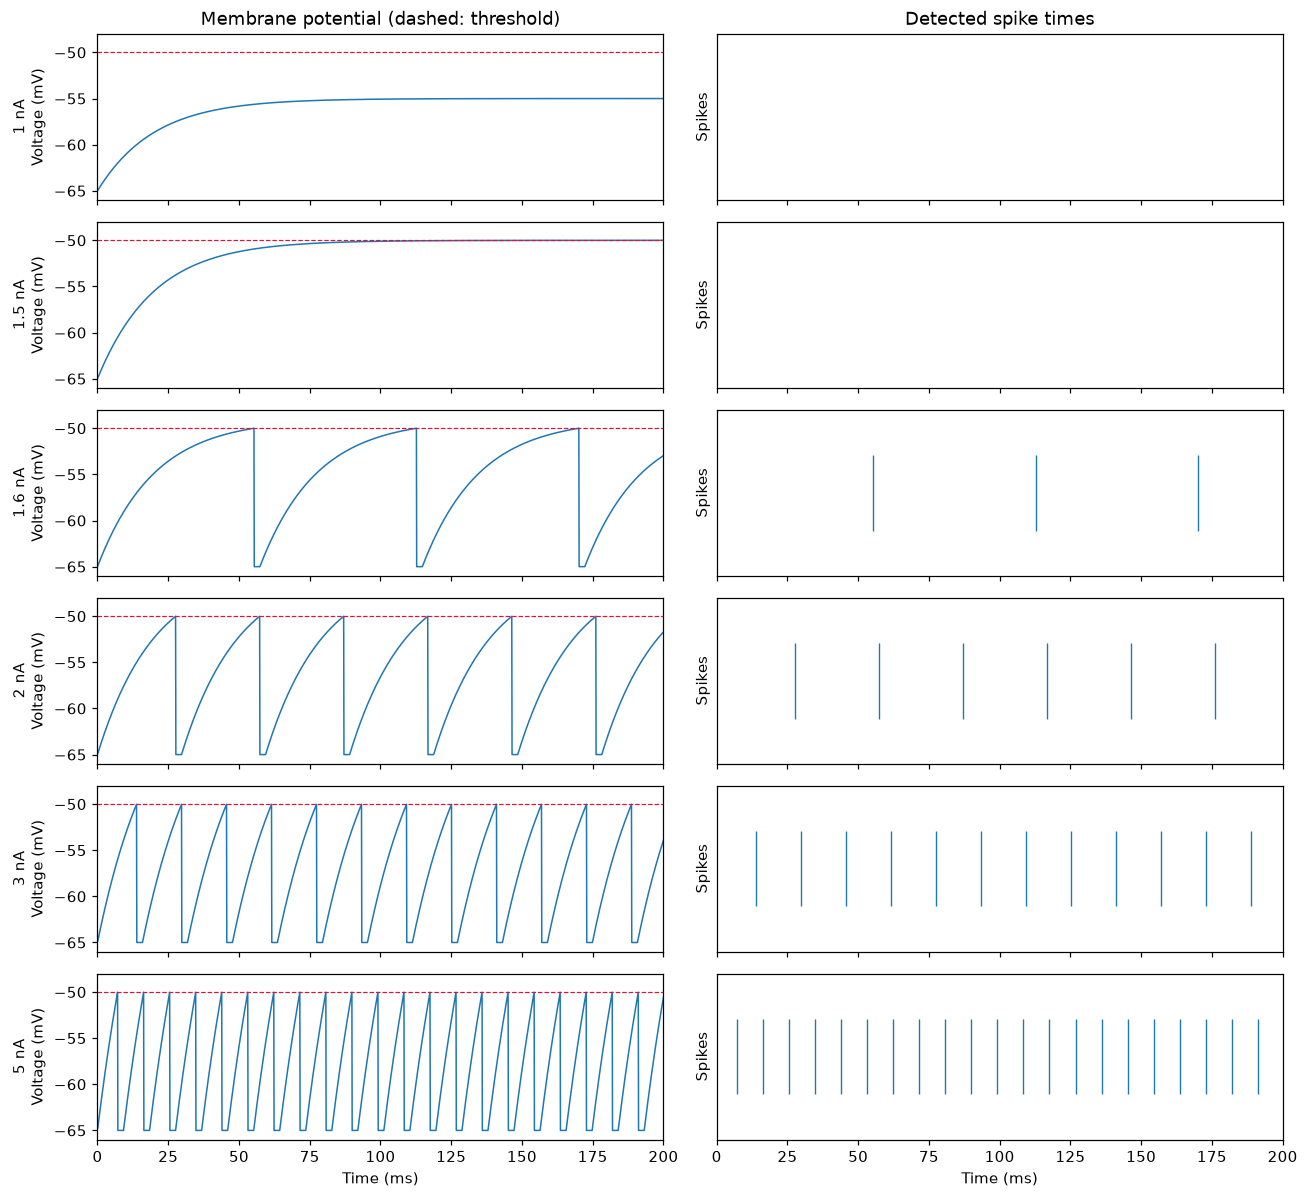

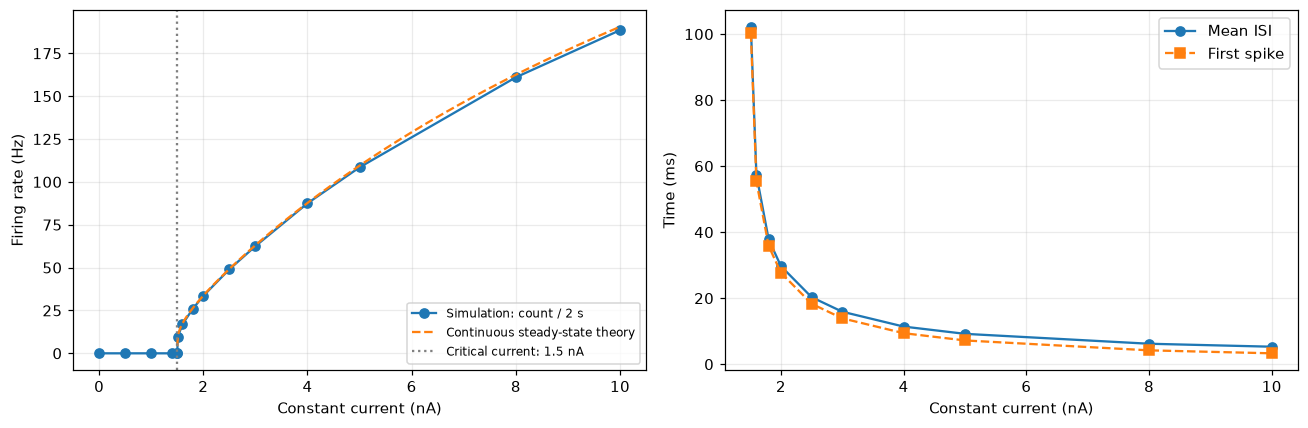

In [4]:
selected = [1, 1.5, 1.6, 2, 3, 5]
fig, axes = plt.subplots(len(selected), 2, figsize=(12, 11), sharex=True)
for row, current in enumerate(selected):
    d = traces[current]
    keep = d['time_ms'] <= 200
    axes[row, 0].plot(d['time_ms'][keep], d['voltage'][keep], lw=1)
    axes[row, 0].axhline(p.threshold, color='crimson', ls='--', lw=0.8)
    axes[row, 0].set(ylabel=f'{current:g} nA\nVoltage (mV)', ylim=(-66, -48))
    times = d['time_ms'][d['spikes'].astype(bool)]
    axes[row, 1].eventplot(times[times <= 200], linewidths=0.9)
    axes[row, 1].set(yticks=[], ylabel='Spikes', xlim=(0, 200))
axes[0, 0].set_title('Membrane potential (dashed: threshold)')
axes[0, 1].set_title('Detected spike times')
for ax in axes[-1]: ax.set_xlabel('Time (ms)')
fig.tight_layout()
fig.savefig(out / 'traces.png', dpi=160)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.linspace(critical + 1e-5, max(currents), 600)
theory = 1000 / (p.refractory + p.tau * np.log(x / (x - critical)))
axes[0].plot(currents, [r['average_rate_Hz'] for r in rows], 'o-', label='Simulation: count / 2 s')
axes[0].plot(x, theory, '--', label='Continuous steady-state theory')
axes[0].axvline(critical, color='gray', ls=':', label='Critical current: 1.5 nA')
axes[0].set(xlabel='Constant current (nA)', ylabel='Firing rate (Hz)')
axes[0].legend(fontsize=8)
active = [r for r in rows if r['mean_ISI_ms'] is not None]
axes[1].plot([r['current_nA'] for r in active], [r['mean_ISI_ms'] for r in active], 'o-', label='Mean ISI')
axes[1].plot([r['current_nA'] for r in active], [r['first_spike_ms'] for r in active], 's--', label='First spike')
axes[1].set(xlabel='Constant current (nA)', ylabel='Time (ms)')
axes[1].legend()
for ax in axes: ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(out / 'rate_vs_current.png', dpi=180)
plt.show()

In [5]:
lookup = {r['current_nA']: r for r in rows}
text = f"""# ?? 2 ?????

## 1. ?????????
????????????????? V_rest + RI??????????????????????????? (?50+65)/10 = **1.5 nA**???? 0?1.5 nA ?????1.51 nA ? 2 ???? {lookup[1.51]['spike_count']} ???? 1.5 nA ??????????????????????????????????????????????

## 2. ??????????????
????????????????????2 nA ??? ISI ? {lookup[2]['mean_ISI_ms']:.2f} ms?3 nA ? {lookup[3]['mean_ISI_ms']:.2f} ms?5 nA ? {lookup[5]['mean_ISI_ms']:.2f} ms?????????????????????? ISI ?? 2 ms?

## 3. ??????????
?????????????????????????????????????????????????????2?3?5 nA ??????????? {lookup[2]['average_rate_Hz']:.1f}?{lookup[3]['average_rate_Hz']:.1f}?{lookup[5]['average_rate_Hz']:.1f} Hz?????????

?????????????????? 1000/2 = 500 Hz ???????????????????? 0.1 ms ???????? 1000/2.1 = 476.2 Hz???????? 10 nA???????????????????????????????????? Euler ??????????????????2 ????? 0.5 Hz ?????

## ????

{table}

?????????? parameters.json???????? traces.npz???????????????????? ISI ????CSV ???
"""
(out / 'analysis.md').write_text(text, encoding='utf-8')
display(Markdown(text))

# ?? 2 ?????

## 1. ?????????
????????????????? V_rest + RI??????????????????????????? (?50+65)/10 = **1.5 nA**???? 0?1.5 nA ?????1.51 nA ? 2 ???? 19 ???? 1.5 nA ??????????????????????????????????????????????

## 2. ??????????????
????????????????????2 nA ??? ISI ? 29.70 ms?3 nA ? 15.90 ms?5 nA ? 9.20 ms?????????????????????? ISI ?? 2 ms?

## 3. ??????????
?????????????????????????????????????????????????????2?3?5 nA ??????????? 33.5?62.5?108.5 Hz?????????

?????????????????? 1000/2 = 500 Hz ???????????????????? 0.1 ms ???????? 1000/2.1 = 476.2 Hz???????? 10 nA???????????????????????????????????? Euler ??????????????????2 ????? 0.5 Hz ?????

## ????

| ?? nA | ???? | ?? Hz | ???? ms | ?? ISI ms |
|---:|---:|---:|---:|---:|
| 0 | 0 | 0.0 | ? | ? |
| 0.5 | 0 | 0.0 | ? | ? |
| 1 | 0 | 0.0 | ? | ? |
| 1.4 | 0 | 0.0 | ? | ? |
| 1.49 | 0 | 0.0 | ? | ? |
| 1.5 | 0 | 0.0 | ? | ? |
| 1.51 | 19 | 9.5 | 100.200 | 102.200 |
| 1.6 | 34 | 17.0 | 55.400 | 57.400 |
| 1.8 | 52 | 26.0 | 35.800 | 37.800 |
| 2 | 67 | 33.5 | 27.700 | 29.700 |
| 2.5 | 98 | 49.0 | 18.300 | 20.300 |
| 3 | 125 | 62.5 | 13.900 | 15.900 |
| 4 | 175 | 87.5 | 9.400 | 11.400 |
| 5 | 217 | 108.5 | 7.200 | 9.200 |
| 8 | 322 | 161.0 | 4.200 | 6.200 |
| 10 | 377 | 188.5 | 3.300 | 5.300 |

?????????? parameters.json???????? traces.npz???????????????????? ISI ????CSV ???
